In [1]:
from collections import Counter

import numpy
import seaborn

from matplotlib import pyplot

from cnn import ResNetFilter
from tree import XGBFilter
from upsilon import UpsilonFilter
from lightcurves import LC_VALIDATION_PATH

In [2]:
LABELS = ['lensing', 'not-lensing']

In [3]:
def plot_confusion(confusion_matrix, title=None):
    pyplot.figure(figsize=(8, 6))
    seaborn.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', 
                xticklabels=LABELS, yticklabels=LABELS)
    pyplot.ylabel('True Label')
    pyplot.xlabel('Predicted Label')
    if title is not None:
        pyplot.title(title)
    pyplot.show()

Loading ...a.validation/lensing:   0%|          | 0/531 [00:00<?, ?it/s]

Loading ...lidation/not-lensing:   0%|          | 0/669 [00:00<?, ?it/s]

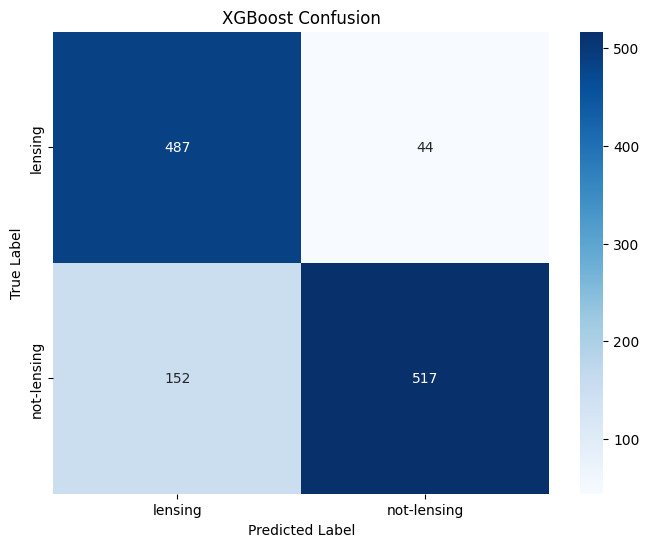

In [4]:
t = XGBFilter()
t_lensing = t.classify_folder(LC_VALIDATION_PATH / 'lensing')
t_not = t.classify_folder(LC_VALIDATION_PATH / 'not-lensing')
t_lensing_labels = Counter([v[0] for v in t_lensing.values()])
t_not_labels = Counter([v[0] for v in t_not.values()])
t_confusion = numpy.array([
    [t_lensing_labels[LABELS[0]], t_lensing_labels[LABELS[1]]],
    [t_not_labels[LABELS[0]], t_not_labels[LABELS[1]]]
])
plot_confusion(t_confusion, "XGBoost Confusion")

Loading ...a.validation/lensing:   0%|          | 0/531 [00:00<?, ?it/s]

Loading ...lidation/not-lensing:   0%|          | 0/669 [00:00<?, ?it/s]

/Users/adam/Code/lc-filter/.venv/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


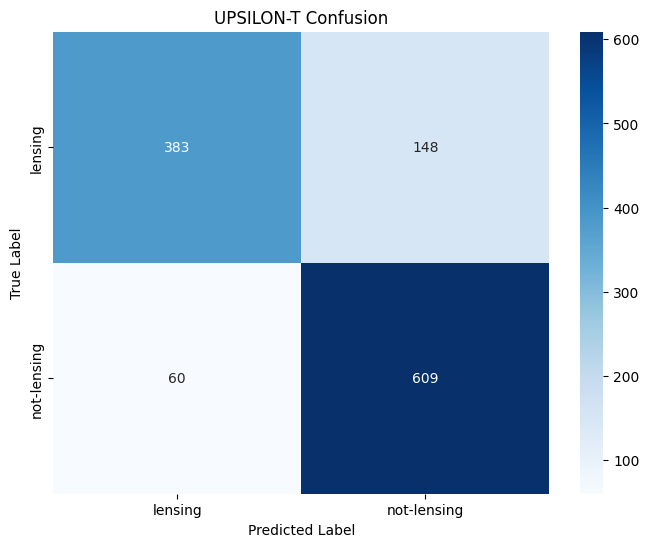

In [5]:
u = UpsilonFilter()
u_lensing = u.classify_folder(LC_VALIDATION_PATH / 'lensing')
u_not = u.classify_folder(LC_VALIDATION_PATH / 'not-lensing')
u_lensing_labels = Counter([v[0] for v in u_lensing.values()])
u_not_labels = Counter([v[0] for v in u_not.values()])
u_confusion = numpy.array([
    [u_lensing_labels[LABELS[0]], u_lensing_labels[LABELS[1]]],
    [u_not_labels[LABELS[0]], u_not_labels[LABELS[1]]]
])
plot_confusion(u_confusion, "UPSILON-T Confusion")

Classify batches:   0%|          | 0/17 [00:00<?, ?it/s]

Classify batches:   0%|          | 0/21 [00:00<?, ?it/s]

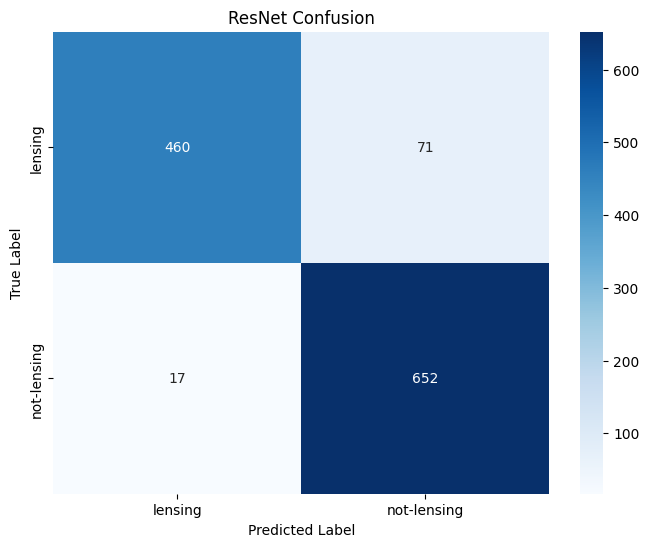

In [6]:
r = ResNetFilter()
r_lensing = r.classify_folder(LC_VALIDATION_PATH / 'lensing')
r_not = r.classify_folder(LC_VALIDATION_PATH / 'not-lensing')
r_lensing_labels = Counter([v[0] for v in r_lensing.values()])
r_not_labels = Counter([v[0] for v in r_not.values()])
r_confusion = numpy.array([
    [r_lensing_labels[LABELS[0]], r_lensing_labels[LABELS[1]]],
    [r_not_labels[LABELS[0]], r_not_labels[LABELS[1]]]
])
plot_confusion(r_confusion, "ResNet Confusion")